# 🐧 Palmer Penguins — Exploratory Data Analysis (EDA)
**Author:** Jean Carlos Rojas Herrera (`RojasJeanDL`) · **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Executive Summary & Business Question
What morphological features distinguish the three penguin species (*Adélie*, *Chinstrap*, *Gentoo*), and how are these features related to each other, island geography, and sex?

This exploratory data analysis demonstrates end-to-end data hygiene, statistical inspection, bias-aware cleaning, and executive data storytelling, including the identification of aggregated statistical anomalies (**Simpson's Paradox**).

## 0. Reproducibility Setup

Every figure in this notebook is rendered by the **same functions** that
`src/generate_charts.py` uses to export the PNGs embedded in the `README.md`.
Nothing is re-implemented here.

This is deliberate. An earlier revision of this project duplicated the plotting
code between the notebook and the export pipeline; a hardcoded legend override
was introduced in both copies and mislabelled two of the three species. A single
source of truth in `src/` makes that class of drift impossible.

In [1]:
import os
import sys

import pandas as pd
import numpy as np

# Resolve the project root so this notebook runs from any working directory
CWD = os.getcwd()
PROJECT_ROOT = os.path.dirname(CWD) if os.path.basename(CWD) == "notebooks" else CWD
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_cleaner import (
    CORE_METRICS,
    clean_penguins_data,
    get_species_morphological_profile,
    load_raw_data,
)
from src.visualization_utils import (
    plot_bill_dimensions_simpson_paradox,
    plot_body_mass_by_species_and_sex,
    plot_correlation_heatmap,
    plot_flipper_length_histogram,
    plot_species_distribution,
    setup_visualization_theme,
)

# Shared colorblind-accessible theme (identical to the exported figures)
setup_visualization_theme(dpi=120, export_dpi=150, palette="colorblind")

# Load the Palmer Penguins dataset (CC0 license, public domain)
df = load_raw_data(os.path.join(PROJECT_ROOT, "data", "penguins.csv"))
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 1. Initial Inspection & Quality Check
We inspect structural dimensions, data types, and initial descriptive statistics to establish a baseline quality report.

In [2]:
print(f"Dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.info()

Dataset dimensions: 344 rows, 8 columns

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [3]:
# Summary statistics for numerical morphological measurements
df.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.00,342.00,342.00,342.00,344.00
mean,43.92,17.15,200.92,4201.75,2008.03
std,5.46,1.97,14.06,801.95,0.82
min,32.10,13.10,172.00,2700.00,2007.00
25%,39.22,15.60,190.00,3550.00,2007.00
50%,44.45,17.30,197.00,4050.00,2008.00
75%,48.50,18.70,213.00,4750.00,2009.00
max,59.60,21.50,231.00,6300.00,2009.00


## 2. Unbiased Data Cleaning Strategy

- **Core missingness:** exactly `2` rows lack *all four* biometric measurements
  (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). These
  are unmeasured birds carrying zero analytical value, so they are dropped —
  leaving `342` observations.
- **Sex imputation avoidance:** `sex` is missing in `11` raw rows (`9` of which
  survive the biometric filter). We deliberately **do not impute** it. Filling
  sex by species mode would manufacture the very sexual-dimorphism signal the
  body-mass analysis is meant to measure. These rows are retained for
  species/island analysis and filtered out locally in sex-stratified charts only.
- **String normalisation:** whitespace stripping across all categorical columns.

The rules live in `src/data_cleaner.py` and are covered by `tests/test_data_cleaner.py`.

In [4]:
missing_counts = df.isna().sum()
print("Missing values per column (raw):")
print(missing_counts[missing_counts > 0].to_string())

df_clean = clean_penguins_data(df)

print(f"\nRows before: {len(df)} | after cleaning: {len(df_clean)}")
print(f"Rows dropped: {len(df) - len(df_clean)}")
print(f"Missing 'sex' retained (NOT imputed): {df_clean['sex'].isna().sum()}")

Missing values per column (raw):
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11

Rows before: 344 | after cleaning: 342
Rows dropped: 2
Missing 'sex' retained (NOT imputed): 9


## 3. Exploratory Analysis by Group
Mean morphological measurements grouped by species expose distinct biological profiles across Adélie, Chinstrap, and Gentoo.

In [5]:
species_profile = get_species_morphological_profile(df_clean)
species_profile

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.79,18.35,189.95,3700.66
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.50,14.98,217.19,5076.02


## 4. Visualizations & Analytical Insights
We present 5 visual analyses, each addressing a specific hypothesis and accompanied by a concise business insight.

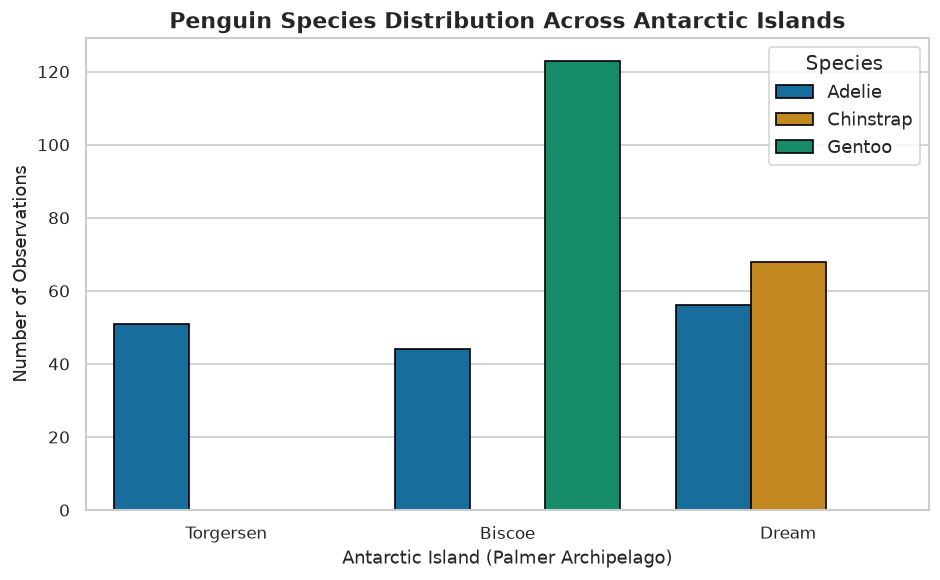

In [6]:
# Viz 1 - Species distribution across islands
_ = plot_species_distribution(df_clean)

### Insight 1: Geographic Species Segregation
*Adélie* penguins are ubiquitous across all three islands (Biscoe, Dream, Torgersen), whereas *Gentoo* are exclusively located on Biscoe and *Chinstrap* solely on Dream. Therefore, **island location alone serves as a strong preliminary predictor** for non-Adélie species.

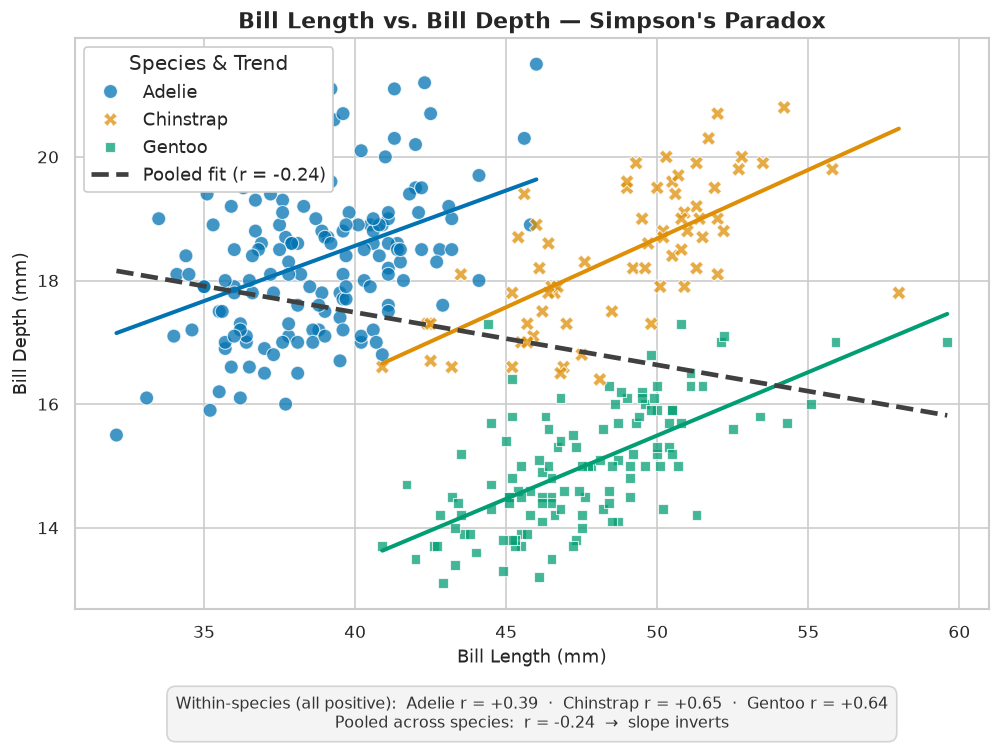

In [7]:
# Viz 2 - Bill length vs. depth, with within-species and pooled OLS fits
_ = plot_bill_dimensions_simpson_paradox(df_clean)

### Insight 2: Simpson's Paradox in Morphological Dimensions

Pooled across the whole population, bill length and bill depth correlate
**negatively** (`r = -0.24`): longer bills appear to be shallower. Stratified by
species, every single subgroup correlates **positively** — Adélie `r = +0.39`,
Chinstrap `r = +0.65`, Gentoo `r = +0.64`.

The sign of the relationship inverts under aggregation. This is a textbook
**Simpson's Paradox**: Gentoo penguins simply have both longer *and* shallower
bills than the other two species, so pooling the groups lets a between-species
offset masquerade as a within-species trend.

**Practical consequence:** any model, metric, or LLM-generated summary built on
the pooled coefficient states the biological relationship backwards.

In [8]:
# Quantifying the paradox rather than asserting it
rows = []
for species, group in df_clean.groupby("species", observed=True):
    rows.append({
        "scope": species,
        "n": len(group),
        "r (bill length ~ depth)": round(
            group["bill_length_mm"].corr(group["bill_depth_mm"]), 3
        ),
    })
rows.append({
    "scope": "POOLED (all species)",
    "n": len(df_clean),
    "r (bill length ~ depth)": round(
        df_clean["bill_length_mm"].corr(df_clean["bill_depth_mm"]), 3
    ),
})
pd.DataFrame(rows).set_index("scope")

,n,r (bill length ~ depth)
scope,,
Adelie,151,0.391
Chinstrap,68,0.654
Gentoo,123,0.643
POOLED (all species),342,-0.235


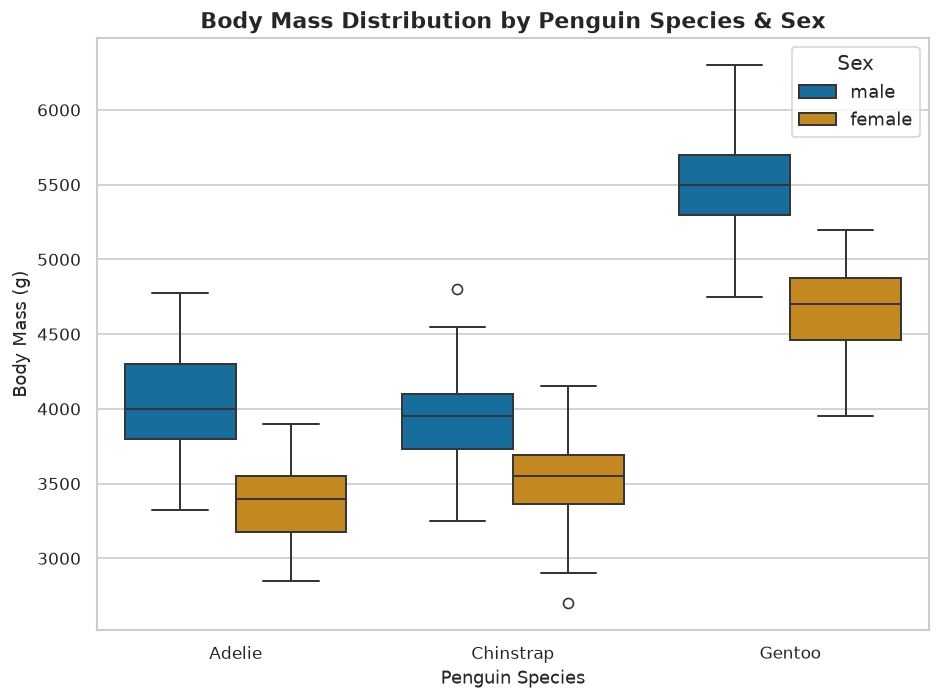

In [9]:
# Viz 3 - Body mass by species and sex
_ = plot_body_mass_by_species_and_sex(df_clean)

### Insight 3: Sexual Dimorphism & Species Mass Hierarchy

*Gentoo* penguins average **5,076 g**, against 3,701 g for Adélie and 3,733 g
for Chinstrap — **+37.2%** and **+36.0%** respectively. Adélie and Chinstrap are
statistically indistinguishable by mass alone (a 32 g gap), so body mass
separates *Gentoo vs. rest*, not all three species.

Within every species, males outweigh females. Any mass-based model must
therefore control for sex, or it will confound sexual dimorphism with species
identity.

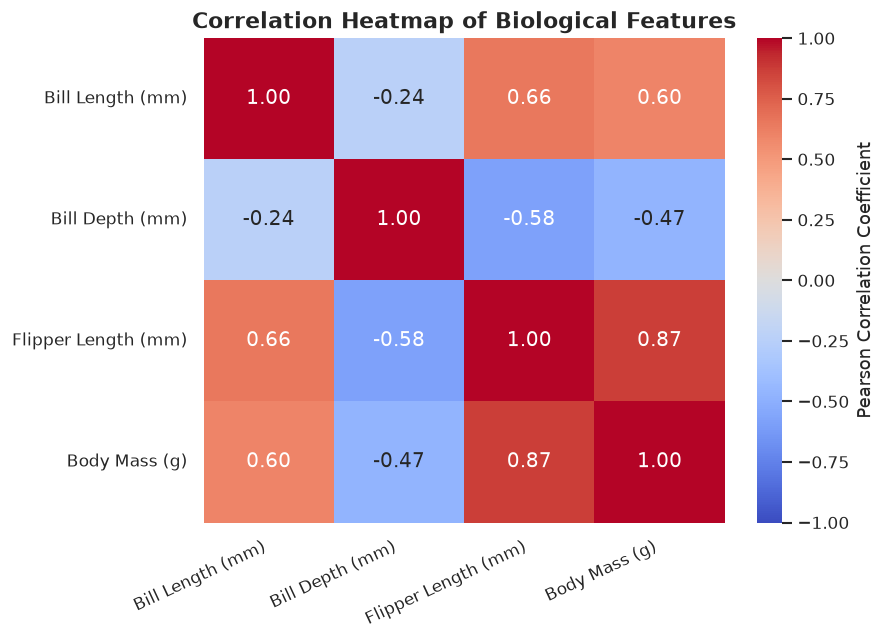

In [10]:
# Viz 4 - Correlation heatmap of numeric features
_ = plot_correlation_heatmap(df_clean)

### Insight 4: Strongest Morphological Coupling
The strongest positive correlation across the entire dataset occurs between **flipper length and body mass (`r = 0.87`)**. Larger birds physically require longer flippers for aquatic locomotion, making flipper length an exceptional single-variable proxy for bird scale.

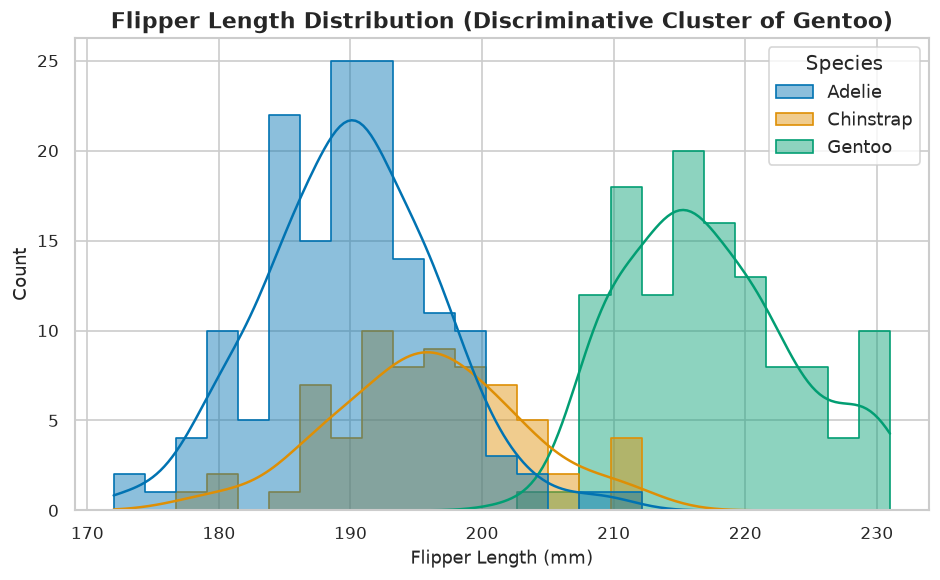

In [11]:
# Viz 5 - Flipper length distribution by species
_ = plot_flipper_length_histogram(df_clean)

### Insight 5: Discriminative Clustering of Gentoo

*Gentoo* flipper lengths form a distinct right-shifted cluster, but the
separation is **not** clean: Gentoo span 203–231 mm while non-Gentoo reach
212 mm, so the two groups overlap in the 203–212 mm band.

Rather than assert a round threshold, we search for the empirically optimal one
below. A single-feature rule at **207 mm** classifies Gentoo vs. non-Gentoo with
**97.7% accuracy** (8 errors in 342 birds). The commonly quoted 210 mm cut-off is
measurably worse (94.4%), because it sacrifices 14 true Gentoo to avoid 2 false
positives.

In [12]:
# Empirical threshold search: is flipper length really a clean discriminator?
is_gentoo = df_clean["species"].eq("Gentoo")

results = []
for threshold in range(195, 226):
    predicted = df_clean["flipper_length_mm"] >= threshold
    false_gentoo = int((predicted & ~is_gentoo).sum())
    missed_gentoo = int((~predicted & is_gentoo).sum())
    results.append({
        "threshold_mm": threshold,
        "false_gentoo": false_gentoo,
        "missed_gentoo": missed_gentoo,
        "errors": false_gentoo + missed_gentoo,
        "accuracy_%": round(
            (len(df_clean) - false_gentoo - missed_gentoo) / len(df_clean) * 100, 1
        ),
    })

threshold_scan = pd.DataFrame(results).set_index("threshold_mm")
best = threshold_scan["errors"].idxmin()

print(f"Gentoo flipper range:     {df_clean[is_gentoo]['flipper_length_mm'].min():.0f}"
      f" - {df_clean[is_gentoo]['flipper_length_mm'].max():.0f} mm")
print(f"Non-Gentoo flipper range: {df_clean[~is_gentoo]['flipper_length_mm'].min():.0f}"
      f" - {df_clean[~is_gentoo]['flipper_length_mm'].max():.0f} mm")
print(f"\nOptimal threshold: {best} mm "
      f"({threshold_scan.loc[best, 'accuracy_%']}% accuracy, "
      f"{threshold_scan.loc[best, 'errors']} misclassified)\n")

threshold_scan.loc[205:213]

Gentoo flipper range:     203 - 231 mm
Non-Gentoo flipper range: 172 - 212 mm

Optimal threshold: 207 mm (97.7% accuracy, 8 misclassified)



,false_gentoo,missed_gentoo,errors,accuracy_%
threshold_mm,,,,
205,11,1,12,96.5
206,8,1,9,97.4
207,7,1,8,97.7
208,6,2,8,97.7
209,5,9,14,95.9
210,5,14,19,94.4
211,1,24,25,92.7
212,1,26,27,92.1
213,0,32,32,90.6


## 5. Executive Conclusions & Next Steps

1. **Geographic filtering is the cheapest classifier.** Island alone resolves
   *Gentoo* (Biscoe only) and *Chinstrap* (Dream only); only Adélie spans all three.
2. **Flipper length is the strongest single feature.** A 207 mm cut-off separates
   Gentoo from non-Gentoo at 97.7% accuracy, and flipper length is the strongest
   correlate of body mass overall (`r = 0.87`).
3. **Aggregation inverts conclusions.** Bill length vs. depth correlates `-0.24`
   pooled and `+0.39 / +0.65 / +0.64` within species. Reporting the pooled figure
   states the biology backwards — the core analytical pitfall this project documents.
4. **Adélie vs. Chinstrap needs bill geometry.** They are near-identical in mass
   (32 g apart) and overlap heavily in flipper length; bill *length* is what
   separates them.

### Next Steps (Modelling)
A supervised classifier (Logistic Regression or Random Forest) over island,
flipper length, bill length and bill depth is the natural follow-up. Accuracy
should be reported from a stratified cross-validated run on held-out folds — not
estimated in advance — and evaluated per class, since Chinstrap is the minority
group (68 of 342 birds) and will dominate the error budget.